![Banner](../images/03_06_banner_spatial_analysis_Segregation.png)







# Local measures of segregation






## Overview

Region-wide indices answer "how segregated is the Buffalo metro area?" with one number. Planners,
health researchers, and housing agencies usually need the follow-up: **where** is it segregated,
and are those places different from what chance alone would produce? Local measures give one
value per tract, ready to map, much like LISA statistics do for spatial autocorrelation.

This notebook follows the PySAL `segregation` tutorial on
[local measures](https://pysal.org/segregation/tutorial.html) using
`geolattice.spatial_analysis.segregation`. Local measures use all five groups (`ALL_GROUPS`) so that
each tract's shares are computed from its full population.

Topics:

- Location quotients and exposure deviations for each group
- Local entropy and Simpson diversity
- Each tract's contribution to the dissimilarity index
- Permutation significance with false-discovery-rate control
- Spatially pooled ("generalized") local measures
- Local change between census years and export to causal models






## Setup

The next cell finds the repository root, puts it on the import path, points `DATA` at
`Data/03_spatial_analysis/data_segregation/buffalo`, imports `geolattice.spatial_analysis.segregation` as `seg`, and loads
the data.

**Study area and data.** The Buffalo-Cheektowaga metropolitan area: Erie and Niagara counties,
New York (about 1.17 million people in 2020). Counts come from the U.S. Census Bureau decennial
censuses of 2000, 2010, and 2020, by census tract, for five mutually exclusive groups:

| Column | Census definition |
|---|---|
| `white` | Not Hispanic or Latino, White alone |
| `black` | Not Hispanic or Latino, Black or African American alone |
| `hispanic` | Hispanic or Latino (any race) |
| `asian` | Not Hispanic or Latino, Asian alone |
| `other` | Everyone else (other single races and two or more races) |

Tract boundaries change between censuses. To compare years on the same units, the 2000 and 2010
counts have been moved onto the 323 tracts of 2020 with dasymetric interpolation weighted by 2020
housing units; notebook 03_07_07 shows how. Tracts with fewer than 100 residents (water, parks,
the airport) are dropped. `Data/03_spatial_analysis/data_segregation/make_buffalo_data.py` rebuilds everything from
the Census files in `Data/03_spatial_analysis/data_segregation/`.

Two map helpers keep every map in the same frame: `add_context(ax)` draws the county outlines,
and `metro_and_core(...)` shows the whole metro area next to a 30 km window centred on the City
of Buffalo, where most tracts are small.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / plotting / tabular stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O for tracts and counties
import matplotlib.pyplot as plt  # figure and axes creation for maps
import numpy as np  # array ops for shares, norms, and masks
import pandas as pd  # tabular display of composition and indices
from IPython.display import display  # rich table previews in the notebook

# Hide library warnings so the notebook output stays readable.
warnings.filterwarnings("ignore")  # run this analysis or plotting step

# ===================================================================
# Setup for Buffalo metro segregation demos.
# Import GeoLattice, point DATA at Data/03_spatial_analysis/data_segregation/buffalo,
# import segregation as seg, load the tract panel, and define map helpers.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Buffalo metro sample data (Erie + Niagara tracts on a shared 2020 geography).
DATA = ROOT / "Data" / "03_spatial_analysis" / "data_segregation" / "buffalo"  # define DATA

# Segregation indices, local measures, profiles, and inference helpers.
from geolattice.spatial_analysis import segregation as seg

# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update(  # run this analysis or plotting step
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
GROUPS = ["white", "black", "hispanic", "asian"]  # main race/ethnicity count columns
ALL_GROUPS = GROUPS + ["other"]  # include residual other category in totals
YEARS = (2000, 2010, 2020)  # panel years available in the sample

# Panel on the 2020 tract geometry (2000 and 2010 interpolated onto it).
tracts = {  # define tracts
    2000: gpd.read_file(DATA / "tracts_2000_on2020.geojson"),  # 2000 counts on 2020 boundaries
    2010: gpd.read_file(DATA / "tracts_2010_on2020.geojson"),  # 2010 counts on 2020 boundaries
    2020: gpd.read_file(DATA / "tracts_2020.geojson"),  # native 2020 tracts
}
counties = gpd.read_file(DATA / "counties.geojson")  # Erie and Niagara outlines
CORE = (662_000, 4_738_000, 692_000, 4_768_000)  # 30 km window on the City of Buffalo (UTM 17N, m)
CITY_HALL = (673_249, 4_750_383)  # City Hall marker for the core window


def add_context(ax, core=False, labels=True):
    """Draw county boundaries and optionally zoom to the City of Buffalo window."""
    counties.boundary.plot(ax=ax, color="0.25", lw=0.8)  # county outlines for context
    if core:  # apply the city-window zoom when requested
        ax.set_xlim(CORE[0], CORE[2])  # zoom to city window
        ax.set_ylim(CORE[1], CORE[3])  # run this analysis or plotting step
        ax.plot(*CITY_HALL, marker="*", color="k", ms=9, mec="white")  # City Hall star
    elif labels:
        for name, (x, y) in {  # iterate over the collection
            "Niagara Co.": (690_000, 4_790_000),  # run this analysis or plotting step
            "Erie Co.": (700_000, 4_715_000),  # run this analysis or plotting step
        }.items():  # run this analysis or plotting step
            ax.text(x, y, name, fontsize=8, color="0.25", ha="center")  # run this analysis or plotting step
    ax.set_axis_off()  # hide coordinate ticks on maps
    return ax  # return the computed result


def metro_and_core(
    gdf, values, title="", cmap="RdBu_r", norm=None, vmin=None, vmax=None,
    label="", significant=None, axes=None,  # define label
):
    """Side-by-side metro-wide and city-window choropleths of the same values."""
    if axes is None:  # create defaults when the caller omitted them
        fig, axes = plt.subplots(  # run this analysis or plotting step
            1, 2, figsize=(13, 6.2),  # run this analysis or plotting step
            gridspec_kw={"width_ratios": [1, 1.25]},  # define gridspec_kw
            constrained_layout=True,  # define constrained_layout
        )
    else:
        fig = axes[0].figure  # figure handle
    g = gdf.assign(_v=np.asarray(values, dtype=float))  # attach plot column
    kw = dict(  # extra keyword arguments for compute()
        column="_v", cmap=cmap, norm=norm,  # define column
        vmin=None if norm else vmin, vmax=None if norm else vmax,  # define vmin
        edgecolor="white", linewidth=0.2,  # define edgecolor
    )
    for ax, core in zip(axes, (False, True)):  # iterate paired sequences together
        g.plot(ax=ax, **kw)  # draw geometries or a series on the axes
        if significant is not None:  # hatch tracts that fail significance
            # Hatch tracts that are not statistically significant.
            g[~np.asarray(significant)].plot(  # draw geometries or a series on the axes
                ax=ax, facecolor="none", edgecolor="0.3", hatch="////", linewidth=0.2  # axes handle for drawing
            )
        add_context(ax, core=core)  # run this analysis or plotting step
    axes[0].set_title(f"{title}\nBuffalo metro (Erie + Niagara)", fontsize=10)  # set labels, title, or axis limits
    axes[1].set_title("City of Buffalo and inner suburbs (star = City Hall)", fontsize=10)  # set labels, title, or axis limits
    sm = plt.cm.ScalarMappable(  # mappable used to draw the colour bar
        cmap=cmap,  # define cmap
        norm=norm or plt.Normalize(  # matplotlib colour normalisation
            vmin if vmin is not None else np.nanmin(values),  # run this analysis or plotting step
            vmax if vmax is not None else np.nanmax(values),  # run this analysis or plotting step
        ),
    )
    fig.colorbar(sm, ax=list(axes), shrink=0.75, label=label)  # attach a colour bar to the figure
    return axes  # return the computed result


print("repo:", ROOT)  # run this analysis or plotting step
print("data:", DATA)  # run this analysis or plotting step
print("geopandas", gpd.__version__, "| CRS", tracts[2020].crs)  # run this analysis or plotting step
print({y: f"{len(g)} tracts, {g.total.sum():,.0f} people" for y, g in tracts.items()})  # run this analysis or plotting step


repo: /home/zia207/Github/GeoLattice
data: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/data_segregation/buffalo
geopandas 1.1.4 | CRS EPSG:26917
{2000: '323 tracts, 1,170,053 people', 2010: '323 tracts, 1,135,475 people', 2020: '323 tracts, 1,166,882 people'}


## Part A: Location quotients

The **location quotient** compares a group's share in a tract with its share in the region:

$$LQ_{ik} = \frac{p_{ik}}{P_k} = \frac{x_{ik}/t_i}{X_k/T}.$$

$LQ > 1$: the group is over-represented in the tract; $LQ < 1$: under-represented; $LQ = 1$: the
tract matches the metro area. Because it is a ratio, the LQ is unbounded above and becomes large for
small groups, a point Part B returns to.






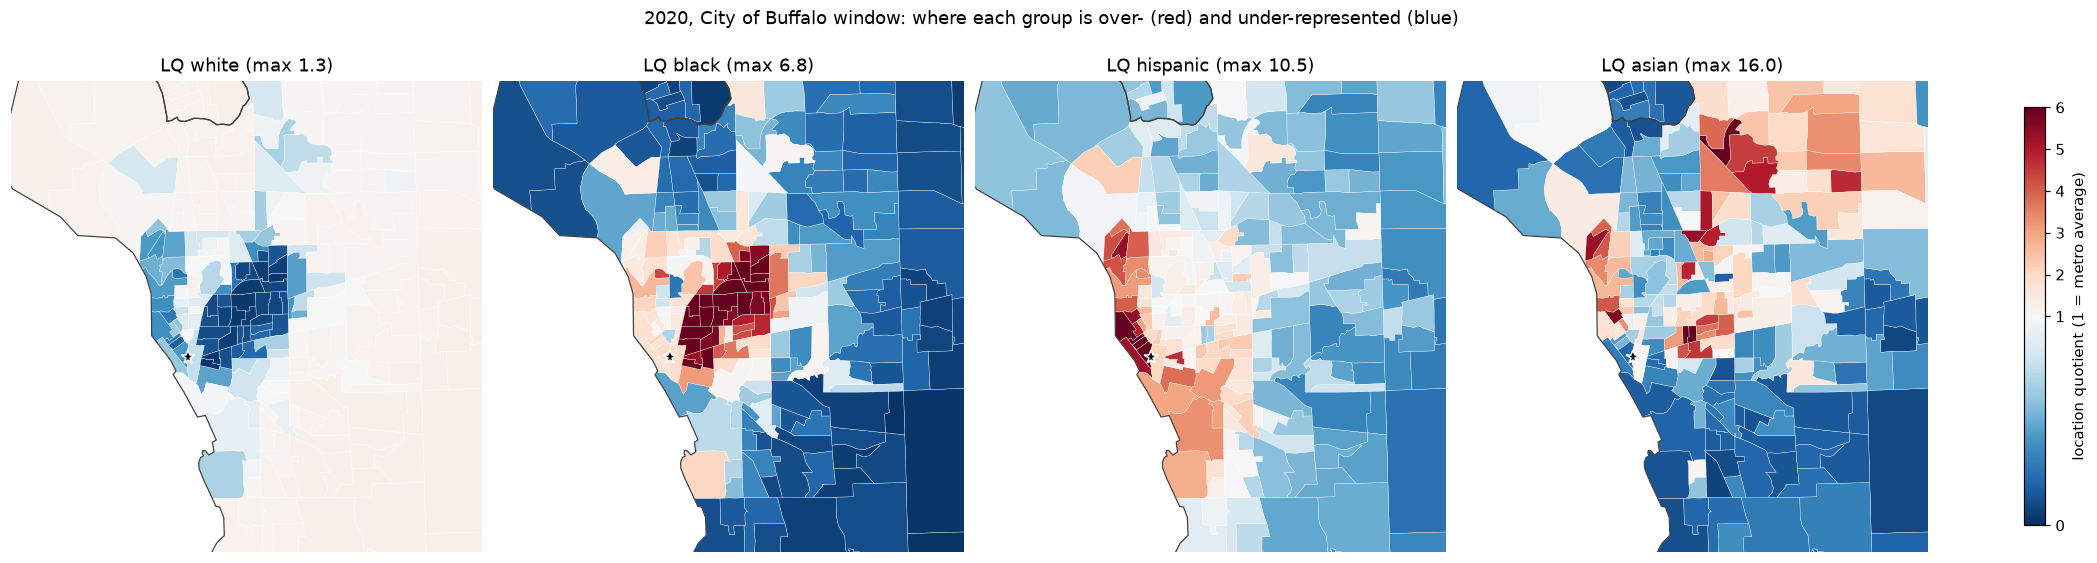

In [2]:
# ===================================================================
# Part A: Location quotients.
# The **location quotient** compares a group's share in a tract with its share in the region:
# ===================================================================

g = tracts[2020]  # working copy of one year's tracts
norm = plt.matplotlib.colors.TwoSlopeNorm(vmin=0, vcenter=1, vmax=6)  # define norm
fig, axes = plt.subplots(1, 4, figsize=(19, 5.4), constrained_layout=True)  # create figure and axes
for ax, grp in zip(axes, GROUPS):  # loop over demographic groups
    lq = seg.local_quotient(g, ALL_GROUPS, grp)  # define lq
    g.assign(lq=lq).plot(column="lq", cmap="RdBu_r", norm=norm, ax=ax, edgecolor="white", linewidth=0.2)  # draw geometries or a series on the axes
    add_context(ax, core=True); ax.set_title(f"LQ {grp} (max {lq.max():.1f})")  # county outlines and optional city zoom
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=axes, shrink=0.75, label="location quotient (1 = metro average)")  # attach a colour bar to the figure
fig.suptitle("2020, City of Buffalo window: where each group is over- (red) and under-represented (blue)")  # run this analysis or plotting step
plt.show()  # render the figure in the notebook



Each group has its own geography in 2020:

- **White** residents are over-represented almost everywhere outside the city core. Because they
  are 73% of the metro area, their LQ cannot exceed about 1.37, so the white map shows mainly
  where white residents are *absent*: the East Side.
- **Black** residents are concentrated on the East Side, north-east of City Hall, with LQ up to
  6.8, meaning tracts that are more than 80% Black.
- **Hispanic** residents are concentrated on the West Side along the Niagara River north of
  downtown (LQ up to 10), with a second, weaker cluster in South Buffalo.
- **Asian** residents form two separate clusters: north of the city around the University at
  Buffalo's North Campus in Amherst, and in city neighbourhoods on the East and West Sides. The two
  clusters most likely reflect different migration streams, university and professional migration
  in the suburbs and refugee resettlement in the city.

## Part B: Exposure deviation and diversity

The **exposure deviation** $p_{ik} - P_k$ carries the same information as the LQ on an additive
scale. It stays bounded in $[-1, 1]$, so it behaves better for small groups: a tract that is 17%
Asian in a metro area that is 4% Asian has $LQ \approx 4$, but a deviation of only 0.13.






In [3]:
# ===================================================================
# Part B: Exposure deviation and diversity.
# Each group has its own geography in 2020:
# ===================================================================

summary = []  # define summary
for grp in GROUPS:  # loop over demographic groups
    lq = seg.local_quotient(g, ALL_GROUPS, grp)  # define lq
    dev = seg.local_exposure_deviation(g, ALL_GROUPS, grp)  # define dev
    summary.append({"group": grp, "metro share": g[grp].sum() / g.total.sum(),  # append this year/group record
                    "LQ min": lq.min(), "LQ max": lq.max(), "LQ cv": lq.std() / lq.mean(),  # run this analysis or plotting step
                    "deviation min": dev.min(), "deviation max": dev.max()})  # run this analysis or plotting step
pd.DataFrame(summary).set_index("group").round(3)  # round for readable display



,metro share,LQ min,LQ max,LQ cv,deviation min,deviation max
group,,,,,,
white,0.730,0.026,1.323,0.410,-0.711,0.236
black,0.125,0.000,6.813,1.459,-0.125,0.728
hispanic,0.058,0.146,10.477,1.100,-0.049,0.548
asian,0.042,0.000,15.961,1.599,-0.042,0.622


The small groups have the most extreme LQs (Asian up to 16, Hispanic up to 10) but much smaller
maximum deviations than the Black group. The LQ describes relative concentration; the deviation
says how many percentage points of a tract's population that concentration represents. Use the
LQ for "how unusual", and the deviation or counts for "how much".

Local **entropy** summarizes all groups at once (see notebook 03_07_02); low values mean a tract
dominated by one group.






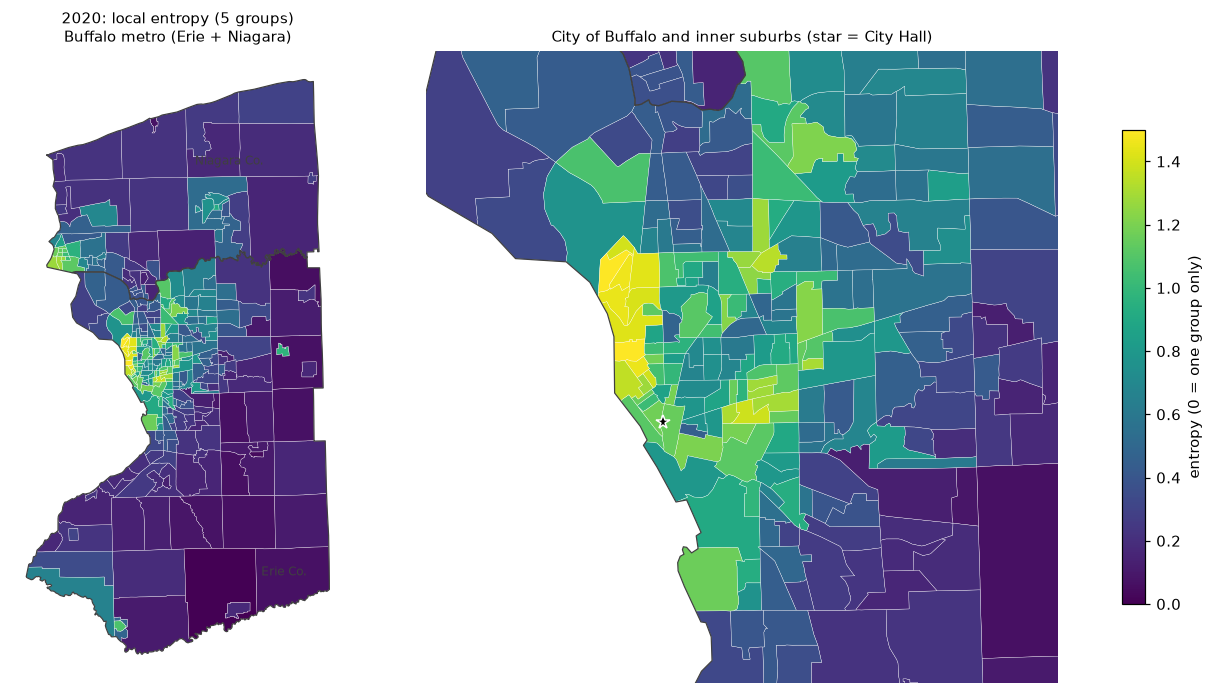

In [4]:
# ===================================================================
# The small groups have the most extreme LQs (Asian up to 16, Hispanic up to 10) but much smaller
# ===================================================================

metro_and_core(g, seg.local_entropy(g, ALL_GROUPS), title="2020: local entropy (5 groups)", cmap="viridis",  # side-by-side metro and city-window choropleths
               vmin=0, vmax=1.5, label="entropy (0 = one group only)")  # define vmin
plt.show()  # render the figure in the notebook



## Part C: Where does dissimilarity come from?

Because $D = \frac{1}{2}\sum_i |x_i/X - y_i/Y|$ is a sum over tracts, each tract's term is its
**contribution** to the metro-wide index. `seg.local_dissimilarity_contribution` returns these
terms (the focal group is `groups[0]`), and they add back to $D$ exactly.






2000: sum of contributions = 0.774057   D = 0.774057   59 tracts make half of D
2010: sum of contributions = 0.729950   D = 0.729950   66 tracts make half of D
2020: sum of contributions = 0.686749   D = 0.686749   68 tracts make half of D


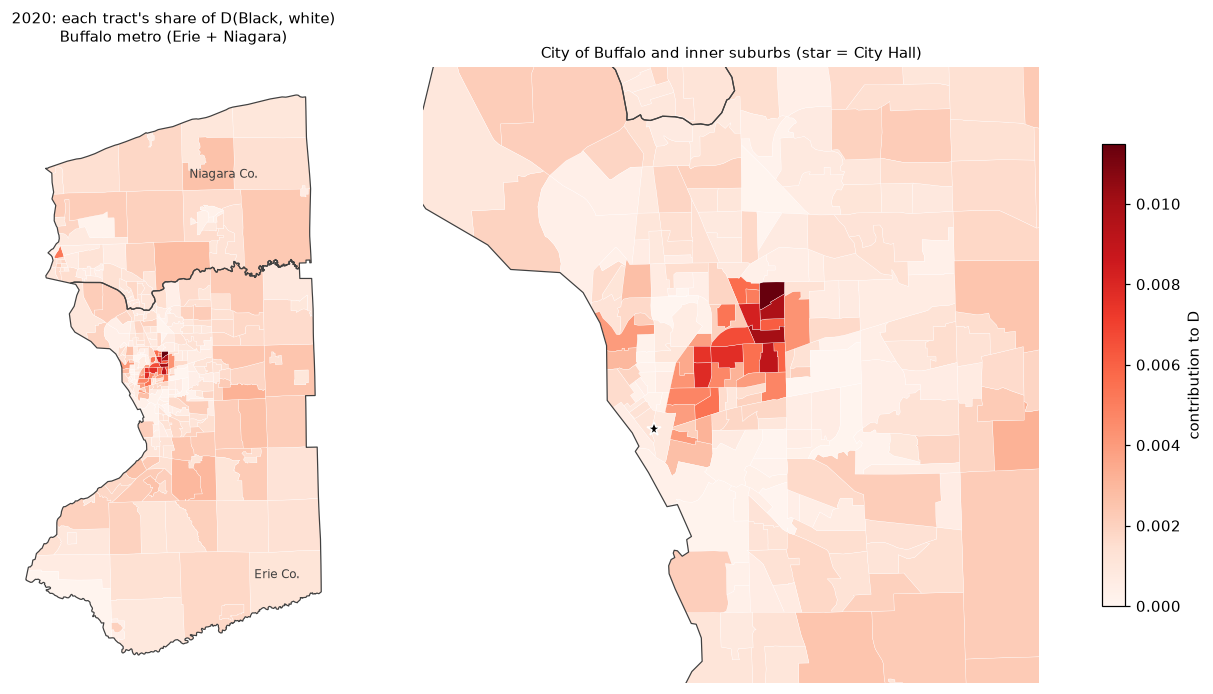

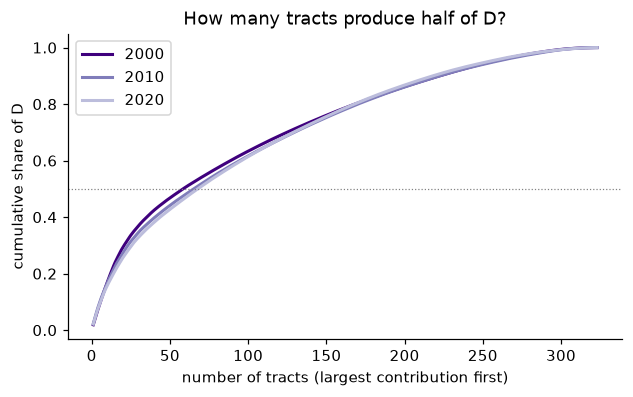

In [5]:
# ===================================================================
# Part C: Where does dissimilarity come from?.
# Because $D = \frac{1}{2}\sum_i |x_i/X - y_i/Y|$ is a sum over tracts, each tract's term is its
# ===================================================================

pair = ["black", "white"]  # focal two-group pairing for D / Gini
contrib = {y: seg.local_dissimilarity_contribution(gg, pair) for y, gg in tracts.items()}  # define contrib
for y, c in contrib.items():  # iterate key/value pairs
    s_ = np.sort(c)[::-1]  # define s_
    print(f"{y}: sum of contributions = {c.sum():.6f}   D = {seg.dissimilarity(tracts[y], pair):.6f}   "  # two-group dissimilarity index D
          f"{np.searchsorted(np.cumsum(s_) / s_.sum(), 0.5) + 1} tracts make half of D")  # run this analysis or plotting step

metro_and_core(g, contrib[2020], title="2020: each tract's share of D(Black, white)", cmap="Reds",  # side-by-side metro and city-window choropleths  # run this analysis or plotting step
               vmin=0, vmax=np.percentile(contrib[2020], 99), label="contribution to D")  # define vmin
plt.show()  # render the figure in the notebook

fig, ax = plt.subplots(figsize=(6.5, 3.6))  # create figure and axes
for y, col in zip(YEARS, ["#3f007d", "#807dba", "#bcbddc"]):  # loop over panel years  # iterate paired sequences together
    s_ = np.sort(contrib[y])[::-1]  # define s_
    ax.plot(np.arange(1, len(s_) + 1), np.cumsum(s_) / s_.sum(), color=col, lw=2, label=str(y))  # draw geometries or a series on the axes
ax.axhline(0.5, color="gray", ls=":", lw=0.8)  # run this analysis or plotting step
ax.set(xlabel="number of tracts (largest contribution first)", ylabel="cumulative share of D",  # set labels, title, or axis limits
       title="How many tracts produce half of D?")  # define title
ax.legend(); plt.show()  # render the figure in the notebook



The largest single contributions come from the East Side core, where each tract's Black share is
far from the metro value; they produce the steep start of the curve. A long tail of suburban
tracts each adds a little. The number of tracts needed for half of $D$ rises from 59 to 68 between
2000 and 2020: the dissimilarity that remains is spread over more tracts as the Black population
disperses beyond the East Side core.

## Part D: Is a local value more extreme than chance?

Every tract has a finite population, so even in a perfectly integrated metro area some tracts would
show $LQ \neq 1$ by chance. `seg.local_significance` tests each tract against an **evenness null**:

1. Keep each tract's total $t_i$.
2. Redraw its group counts from a multinomial with the metro proportions $P_k$ (999 times).
3. Compare the observed statistic with that tract's simulated distribution (pseudo p-value).
4. Apply the Benjamini-Hochberg **false-discovery-rate** correction across all 323 tests.

Step 4 matters. At $\alpha = 0.05$ about 5% of tracts would be "significant" by chance alone
without a correction, the same multiple-testing problem that LISA cluster maps face.

### D1. Choose a statistic centred on zero

With `alternative="two-sided"` the test counts a simulation as "at least as extreme" when
$|\text{null}| \ge |\text{observed}|$. That is correct for a statistic centred on 0, such as
the exposure deviation $p_{ik} - P_k$. The LQ is centred on **1** and always positive, so a
two-sided test on the LQ can only ever flag *over*-representation. The cell shows the consequence.






In [6]:
# ===================================================================
# Part D: Is a local value more extreme than chance?.
# The largest single contributions come from the East Side core, where each tract's Black share is
# ===================================================================

lq_test = seg.local_significance(g, ALL_GROUPS, seg.local_quotient, group="black", permutations=999, seed=42)  # define lq_test
dev_test = seg.local_significance(g, ALL_GROUPS, seg.local_exposure_deviation, group="black", permutations=999, seed=42)  # define dev_test
pd.DataFrame({  # run this analysis or plotting step
    "LQ, two-sided": {"over-represented (sig.)": int((lq_test.significant_fdr & (lq_test.statistic > 1)).sum()),  # run this analysis or plotting step
                      "under-represented (sig.)": int((lq_test.significant_fdr & (lq_test.statistic < 1)).sum())},  # run this analysis or plotting step
    "deviation, two-sided": {"over-represented (sig.)": int((dev_test.significant_fdr & (dev_test.statistic > 0)).sum()),  # run this analysis or plotting step
                             "under-represented (sig.)": int((dev_test.significant_fdr & (dev_test.statistic < 0)).sum())},  # run this analysis or plotting step
})


,"LQ, two-sided","deviation, two-sided"
over-represented (sig.),97,98
under-represented (sig.),0,218


The LQ test misses every tract where Black residents are significantly *under*-represented,
although most suburban tracts clearly are. The deviation test finds both sides. Two safe options:
test the deviation two-sided (used below), or test the LQ twice with `alternative="greater"` and
`alternative="less"`.

### D2. Significance in each year






In [7]:
# ===================================================================
# D2. Significance in each year.
# The LQ test misses every tract where Black residents are significantly *under*-represented,
# ===================================================================

sig = {}  # define sig
for y in YEARS:  # loop over panel years
    sig[y] = seg.local_significance(tracts[y], ALL_GROUPS, seg.local_exposure_deviation, group="black",  # assign a derived column or cell
                                    permutations=999, alpha=0.05, seed=42)  # define permutations
counts = pd.DataFrame.from_dict(orient="index", data={  # build table counts
    y: {"p < 0.05 (uncorrected)": int((s.p_value < 0.05).sum()),  # run this analysis or plotting step
        "significant after FDR": int(s.significant_fdr.sum()),  # run this analysis or plotting step
        "of which over-represented": int((s.significant_fdr & (s.statistic > 0)).sum()),  # run this analysis or plotting step
        "of which under-represented": int((s.significant_fdr & (s.statistic < 0)).sum()),  # run this analysis or plotting step
        "not significant": int((~s.significant_fdr).sum())}  # run this analysis or plotting step
    for y, s in sig.items()  # iterate key/value pairs
})
counts


,p < 0.05 (uncorrected),significant after FDR,of which over-represented,of which under-represented,not significant
2000,318,318,80,238,5
2010,318,318,94,224,5
2020,316,316,98,218,7


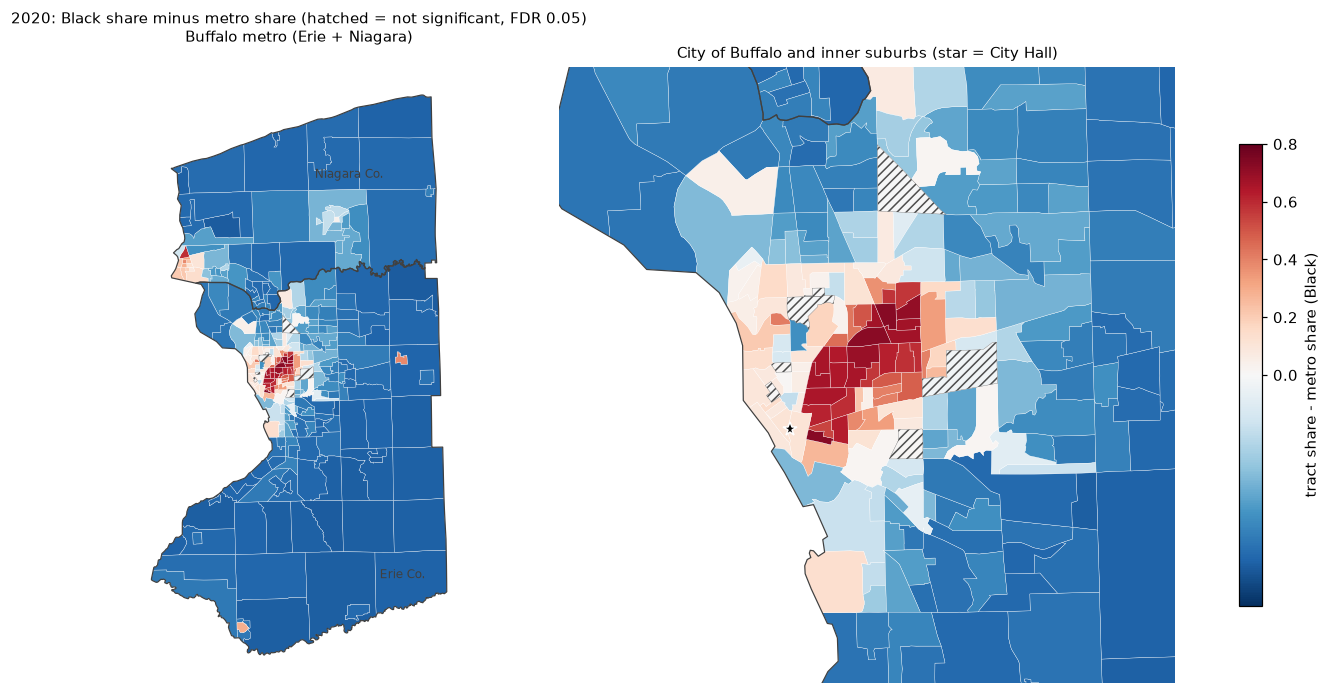

In [8]:
norm = plt.matplotlib.colors.TwoSlopeNorm(vmin=-0.15, vcenter=0, vmax=0.8)  # define norm
metro_and_core(g, sig[2020]["statistic"], significant=sig[2020]["significant_fdr"], cmap="RdBu_r", norm=norm,  # side-by-side metro and city-window choropleths
               title="2020: Black share minus metro share (hatched = not significant, FDR 0.05)",  # define title
               label="tract share - metro share (Black)")  # define label
plt.show()  # render the figure in the notebook



Almost every tract is significant in every year, and about two thirds of significant tracts are
ones where Black residents are *under*-represented, mostly the suburban ring. With a median of
about 3,400 residents per tract, a random draw almost never strays more than a few percentage
points from the metro share, so even moderate real differences are detectable. Only a handful of
tracts, mostly in the transition zone around the East Side, are indistinguishable from the metro
average. Statistical significance says a tract is not a random draw of the metro population; the
magnitude of the deviation says whether the difference matters. Report both.

> **What the evenness null does and does not test.** It asks whether the tract differs from a
> random draw of residents. It does not ask whether the *spatial pattern* of tracts is unusual;
> for that, use the systematic or spatially constrained nulls in notebook 03_07_05.

### D3. Significance for every group






,significantly over-represented,significantly under-represented,not significant
group,,,
white,200,114,9
black,98,218,7
hispanic,86,188,49
asian,78,225,20


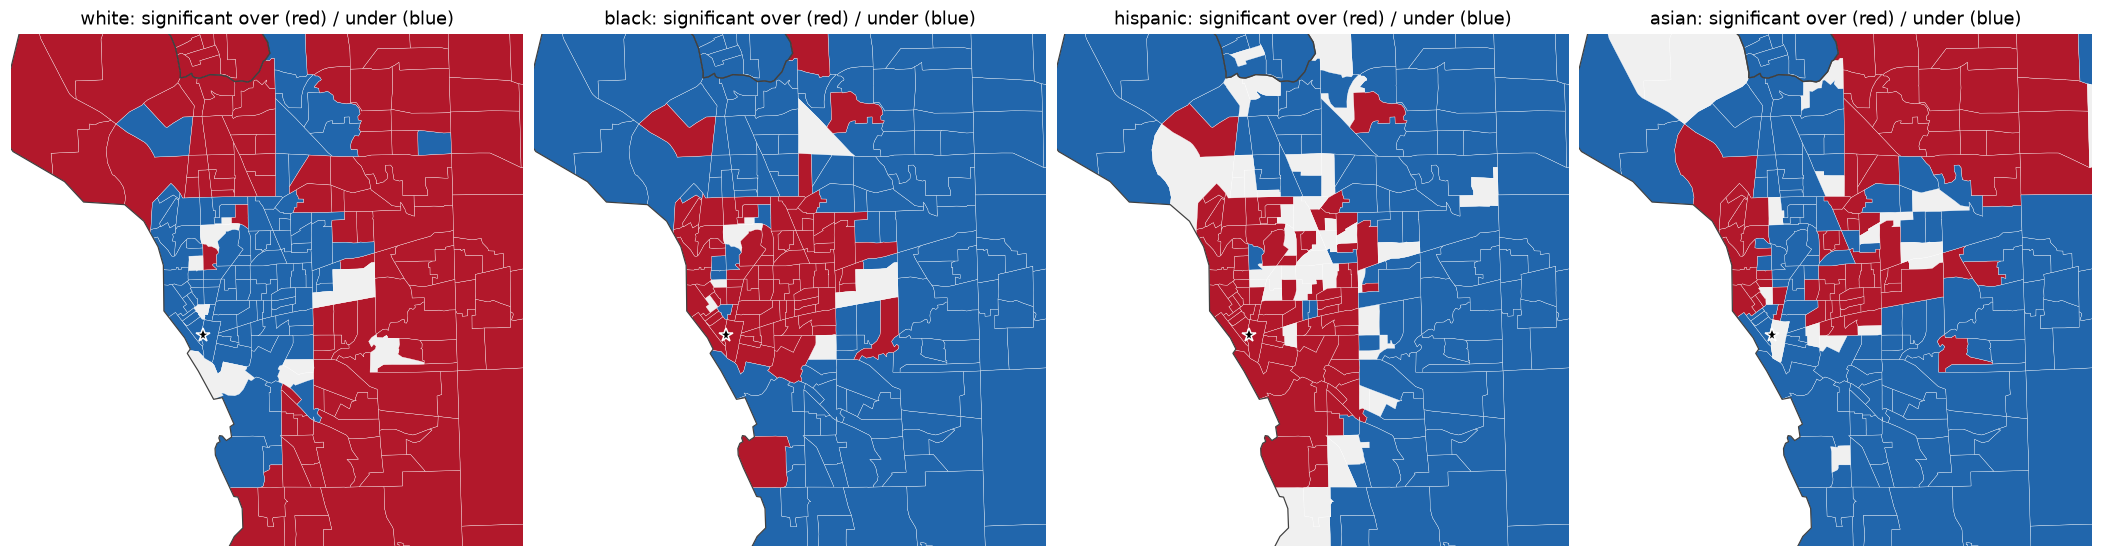

In [9]:
# ===================================================================
# D3. Significance for every group.
# Almost every tract is significant in every year, and about two thirds of significant tracts are
# ===================================================================

rows, sig_all = [], {}
for grp in GROUPS:  # loop over demographic groups
    s = seg.local_significance(g, ALL_GROUPS, seg.local_exposure_deviation, group=grp, permutations=499, seed=7)  # define s
    sig_all[grp] = s  # assign a derived column or cell
    rows.append({"group": grp, "significantly over-represented": int((s.significant_fdr & (s.statistic > 0)).sum()),  # append this year/group record
                 "significantly under-represented": int((s.significant_fdr & (s.statistic < 0)).sum()),  # run this analysis or plotting step
                 "not significant": int((~s.significant_fdr).sum())})  # run this analysis or plotting step
display(pd.DataFrame(rows).set_index("group"))  # show a rich table preview

fig, axes = plt.subplots(1, 4, figsize=(19, 5.4), constrained_layout=True)  # create figure and axes
cat_cmap = plt.matplotlib.colors.ListedColormap(["#2166ac", "#f0f0f0", "#b2182b"])  # define cat_cmap
for ax, grp in zip(axes, GROUPS):  # loop over demographic groups
    s = sig_all[grp]  # define s
    cls = np.where(~s.significant_fdr, 1, np.where(s.statistic > 0, 2, 0))  # define cls
    g.assign(c=cls).plot(column="c", cmap=cat_cmap, vmin=0, vmax=2, ax=ax, edgecolor="white", linewidth=0.2)  # draw geometries or a series on the axes
    add_context(ax, core=True); ax.set_title(f"{grp}: significant over (red) / under (blue)")  # county outlines and optional city zoom
plt.show()  # render the figure in the notebook


Significance maps for the four groups side by side show the structure behind the indices.
White over-representation (red) covers the suburbs, Black over-representation the East Side,
Hispanic over-representation the West Side and South Buffalo, and Asian over-representation both
Amherst and pockets of the city. More tracts are non-significant for the Hispanic and Asian groups
because, being smaller, their tract counts are noisier.

## Part E: Spatially pooled local measures

A tract boundary is an administrative line. Residents experience the surrounding area too.
Passing a `Neighborhood` to any local function pools counts from nearby tracts before computing
the statistic:

$$\tilde{x}_{ik} = x_{ik} + \sum_j w_{ij}\,x_{jk}\quad\text{(weights row-standardized)}.$$

`seg.kernel_weights` uses a distance-decay kernel; `seg.knn_weights` uses the $k$ nearest tracts.






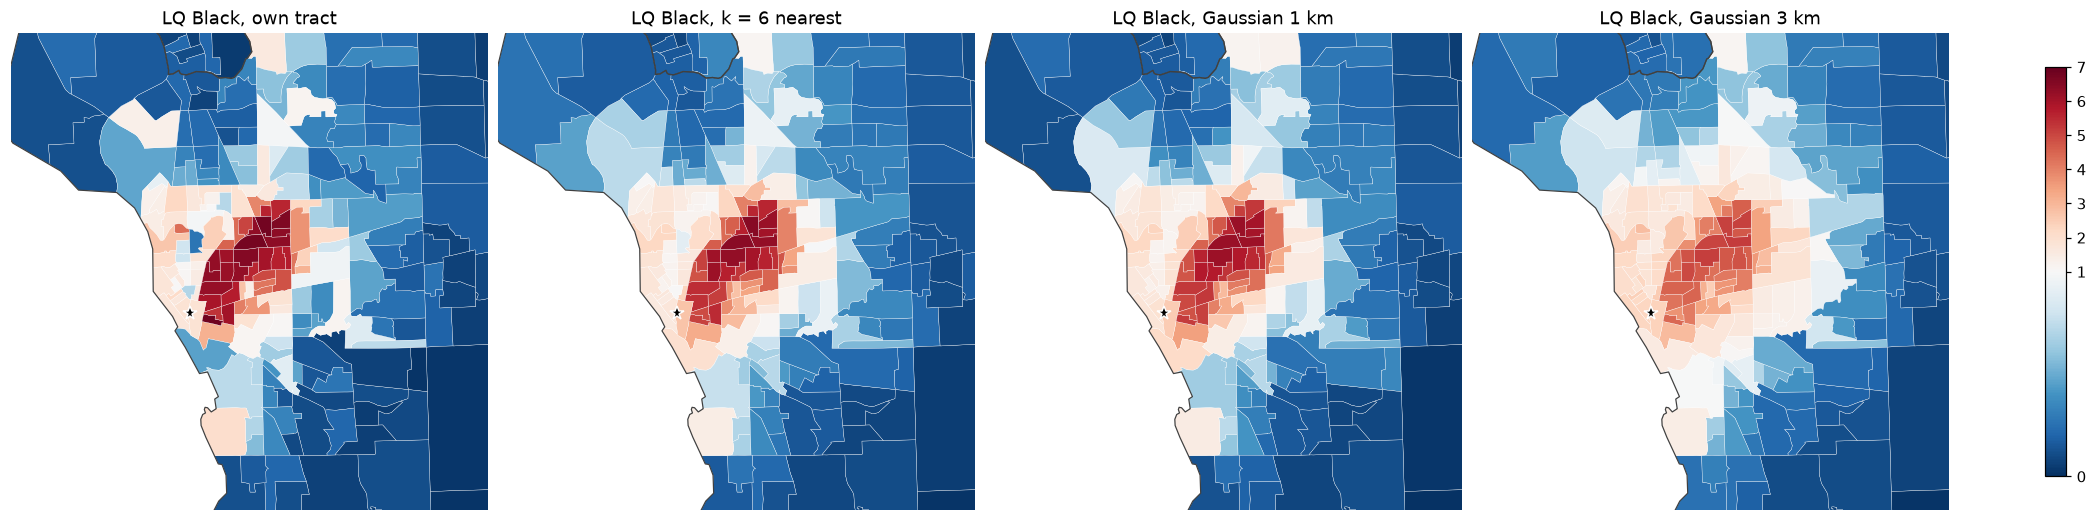

,LQ std,LQ max,tracts with LQ > 2
neighbourhood,,,
own tract,1.771,6.813,61
k = 6 nearest,1.630,6.471,63
Gaussian 1 km,1.617,6.191,70
Gaussian 3 km,1.361,5.182,75


In [10]:
# ===================================================================
# Part E: Spatially pooled local measures.
# Significance maps for the four groups side by side show the structure behind the indices.
# ===================================================================

neighbourhoods = {  # define neighbourhoods
    "own tract": None,
    "k = 6 nearest": seg.knn_weights(g, k=6),  # run this analysis or plotting step
    "Gaussian 1 km": seg.kernel_weights(g, bandwidth=1000),  # distance-decay neighbourhood weights
    "Gaussian 3 km": seg.kernel_weights(g, bandwidth=3000),  # distance-decay neighbourhood weights
}
fig, axes = plt.subplots(1, 4, figsize=(19, 5.4), constrained_layout=True)  # create figure and axes
norm = plt.matplotlib.colors.TwoSlopeNorm(vmin=0, vcenter=1, vmax=7)  # define norm
rows = []  # accumulate one summary row per year / group
for ax, (name, nb) in zip(axes, neighbourhoods.items()):  # pair each axis with a year or layer
    lq = seg.local_quotient(g, ALL_GROUPS, "black", neighborhood=nb)  # define lq
    g.assign(v=lq).plot(column="v", cmap="RdBu_r", norm=norm, ax=ax, edgecolor="white", linewidth=0.2)  # draw geometries or a series on the axes
    add_context(ax, core=True); ax.set_title(f"LQ Black, {name}")  # county outlines and optional city zoom
    rows.append({"neighbourhood": name, "LQ std": lq.std(), "LQ max": lq.max(),  # append this year/group record
                 "tracts with LQ > 2": int((lq > 2).sum())})  # run this analysis or plotting step
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=axes, shrink=0.7)  # attach a colour bar to the figure
plt.show()  # render the figure in the notebook
pd.DataFrame(rows).set_index("neighbourhood").round(3)  # round for readable display


Pooling smooths tract-level differences and spreads the East Side cluster over its neighbours:
the maximum LQ falls from 6.8 to 5.2 with a 3 km kernel, while the number of tracts with LQ
above 2 *rises* from 61 to 75 as the surroundings of the core are drawn in. The broader the
neighbourhood, the more the map reflects the macro-scale structure rather than individual tracts.
The same `neighborhood=` argument works inside `local_significance`, but those p-values are
optimistic, because pooled counts are larger and neighbouring tracts share residents; notebook
03_07_05 discusses better nulls.

## Part F: Local change between census years

Because the three years share the 2020 tract geometry, local measures can be differenced tract by
tract.






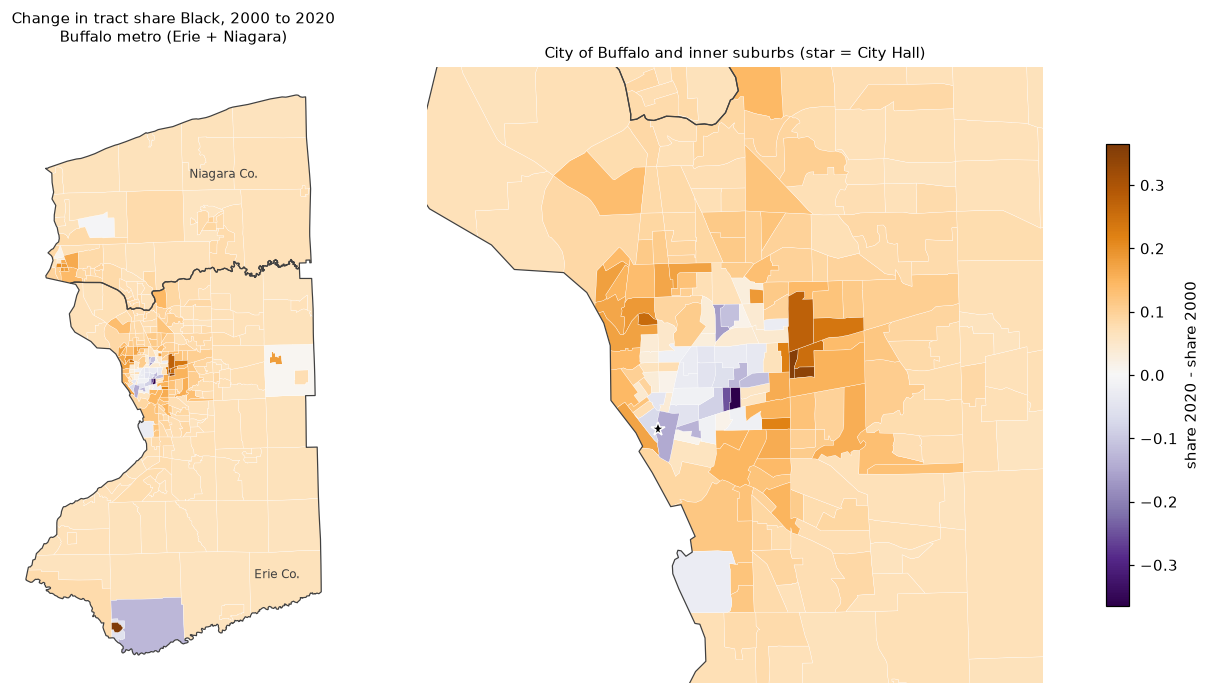

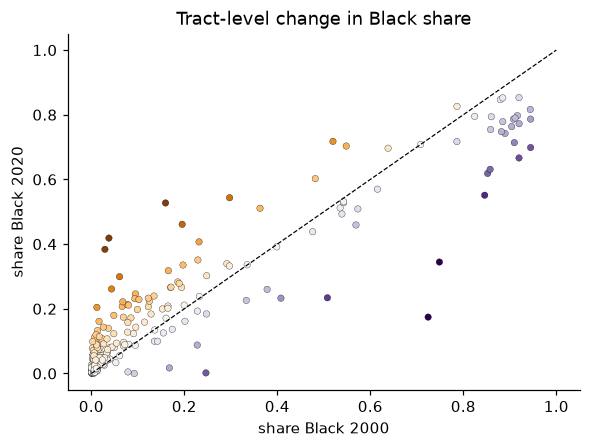

,tracts,mean change in share,Black pop change
"(-0.001, 0.05]",214,0.027,21473.0
"(0.05, 0.2]",51,0.066,10257.0
"(0.2, 0.5]",20,-0.001,-2188.0
"(0.5, 0.8]",16,-0.073,-3442.0
"(0.8, 1.0]",22,-0.141,-14662.0


In [11]:
# ===================================================================
# Part F: Local change between census years.
# Pooling smooths tract-level differences and spreads the East Side cluster over its neighbours:
# ===================================================================

dev = {y: seg.local_exposure_deviation(tracts[y], ALL_GROUPS, "black") for y in YEARS}  # define dev
share = {y: tracts[y].black / tracts[y].total for y in YEARS}  # define share
change = share[2020] - share[2000]  # define change
lim = np.nanpercentile(np.abs(change), 99)  # define lim
metro_and_core(g, change, title="Change in tract share Black, 2000 to 2020", cmap="PuOr_r",  # side-by-side metro and city-window choropleths
               vmin=-lim, vmax=lim, label="share 2020 - share 2000")  # define vmin
plt.show()  # render the figure in the notebook

fig, ax = plt.subplots(figsize=(6, 4.2))  # create figure and axes
sc = ax.scatter(share[2000], share[2020], c=change, cmap="PuOr_r", vmin=-lim, vmax=lim, s=18, edgecolor="k", lw=0.2)  # define sc
ax.plot([0, 1], [0, 1], "k--", lw=0.8)  # draw geometries or a series on the axes
ax.set(xlabel="share Black 2000", ylabel="share Black 2020", title="Tract-level change in Black share")  # set labels, title, or axis limits
plt.show()  # render the figure in the notebook
bins = pd.cut(share[2000], [0, 0.05, 0.2, 0.5, 0.8, 1.0], include_lowest=True)  # define bins
pd.DataFrame({"tracts": bins.value_counts().sort_index(),  # run this analysis or plotting step
              "mean change in share": change.groupby(bins, observed=True).mean().round(3),  # field in the summary row
              "Black pop change": (tracts[2020].black - tracts[2000].black).groupby(bins, observed=True).sum().round(0)})  # field in the summary row



The change map and the table show **deconcentration**. Tracts that were more than 80% Black in
2000 lost about 14,700 Black residents and their average Black share fell by 14 percentage points.
Tracts that were less than 5% Black gained about 21,500 Black residents, mostly in the inner
suburbs east and north of the city (orange), although their shares rose only modestly because
they are large and populous. This is how $D$ fell: not by integration of the East Side core, but by
movement out of it into areas that were nearly all white.

## Part G: Local segregation as a model variable

`seg.export_for_causal` returns a geometry-free table keyed by tract id: the shape that
`geolattice.spatial_analysis.spatialcausal` and PyCausalML expect for an exposure or confounder column. Stacking the
years gives a tract-by-year panel ready to merge with health, school, or housing outcomes by
`tract_id`.






In [12]:
# ===================================================================
# Part G: Local segregation as a model variable.
# The change map and the table show **deconcentration**. Tracts that were more than 80% Black in
# ===================================================================

panel = []  # define panel
for y in YEARS:  # loop over panel years
    gg = tracts[y]  # tracts GeoDataFrame for this panel
    t_ = seg.export_for_causal(gg, seg.local_exposure_deviation(gg, ALL_GROUPS, "black"), id_col="tract_id", name="dev_black")  # exposure metrics for one group across years
    t_["lq_black"] = seg.local_quotient(gg, ALL_GROUPS, "black")  # assign a derived column or cell
    t_["entropy"] = seg.local_entropy(gg, ALL_GROUPS)  # assign a derived column or cell
    t_["lq_black_pooled_1km"] = seg.local_quotient(gg, ALL_GROUPS, "black",  # assign a derived column or cell
                                                   neighborhood=seg.kernel_weights(gg, bandwidth=1000))  # distance-decay neighbourhood weights
    t_["year"] = y  # assign a derived column or cell
    panel.append(t_)  # append this year/group record
panel = pd.concat(panel, ignore_index=True)  # define panel
print(panel.shape)  # status line for the notebook reader
panel.head()  # run this analysis or plotting step



(969, 6)


,tract_id,dev_black,lq_black,entropy,lq_black_pooled_1km,year
0,36029009112,-0.086660,0.246914,0.497187,0.383126,2000
1,36029003800,0.404531,4.515415,0.882248,4.744287,2000
2,36029006301,0.020566,1.178722,0.907077,1.334825,2000
3,36029011400,-0.111319,0.032627,0.204696,0.044194,2000
4,36029010805,-0.109319,0.050007,0.142050,0.081542,2000


## Summary

- **Location quotients** and **exposure deviations** show where each group is over- or
  under-represented. The LQ is relative and large for small groups; the deviation is bounded.
- **Local entropy** summarizes all groups; low values flag single-group tracts, in Buffalo both
  the suburban ring and the East Side core.
- **Dissimilarity contributions** add up to $D$ exactly, showing which tracts produce the
  metro-wide index.
- **Permutation tests with FDR correction** separate real local concentration from small-number
  noise. Correct for running one test per tract, use a zero-centred statistic (or two one-sided
  tests) for two-sided questions, and report magnitudes next to significance.
- **Pooled local measures** describe the residential environment rather than the tract, and the
  choice of neighbourhood changes the map.
- Local measures on shared boundaries can be **differenced across years** and exported as a
  tract-by-year panel for modelling.

**Next:** 03_07_04 turns the neighbourhood size itself into the object of study with multiscale
segregation profiles.

## References

- Anselin, L. (1995). Local indicators of spatial association: LISA. *Geographical Analysis*, 27(2), 93-115.
- Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate. *Journal of the Royal Statistical Society B*, 57(1), 289-300.
- Reardon, S. F., & O'Sullivan, D. (2004). Measures of spatial segregation. *Sociological Methodology*, 34(1), 121-162.
- Wong, D. W. S. (2002). Modeling local segregation: a spatial interaction approach. *Geographical and Environmental Modelling*, 6(1), 81-97.




